# Chapitre 1 - Cours 5 : scalabilité et maintenabilité

Un système fiable aujourd'hui ne le sera pas forcément demain si la charge augmente : la
**scalabilité** désigne sa capacité à faire face à cette croissance. Et un système qui
vit longtemps coûte surtout en **maintenance** : il doit rester exploitable,
compréhensible et modifiable. Ce notebook couvre la sous-section *Approaches for Coping with Load* de la section *Scalability*, la section *Maintainability* (*Operability*, *Simplicity*, *Evolvability*), ainsi que les architectures à mémoire partagée, à disques partagés et sans partage que le livre présente dans l'introduction de sa partie II.

**Plan.**

1. Qu'est-ce que la scalabilité ? Charge, ressources et performance.
2. Monter en gamme ou multiplier les machines : mémoire partagée, disques partagés, rien de partagé.
3. Les limites de la parallélisation : loi d'Amdahl et loi universelle de scalabilité.
4. Pas de recette magique : principes, élasticité et ordres de grandeur.
5. Opérabilité : faciliter la vie de l'exploitation.
6. Simplicité : maîtriser la complexité.
7. Évolutivité : faciliter le changement.

In [1]:
import math

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Qu'est-ce que la scalabilité ? (section *Scalability*)

Dire « X est scalable » ou « Y ne passe pas à l'échelle » n'a pas de sens : la
scalabilité n'est pas une étiquette, c'est une série de questions. Si le système grandit
de telle façon, quelles options avons-nous ? Comment ajouter des ressources pour suivre ?
Au rythme actuel, quand atteindrons-nous les limites de l'architecture ?

Une fois la charge décrite par ses **paramètres** (cours 1), le livre propose deux
façons de regarder sa croissance :

1. à **ressources constantes**, comment la performance se dégrade-t-elle quand la charge
   augmente ? (c'est la courbe en crosse de hockey du cours 3) ;
2. à **performance constante**, de combien faut-il augmenter les ressources ?

Répondons à la seconde question pour le service du cours 3 (requêtes de 10 ms de CPU) :
combien de cœurs faut-il pour que moins de 1 % des requêtes attendent plus de 5 ms,
quand la charge passe de 100 à 100 000 requêtes par seconde ?

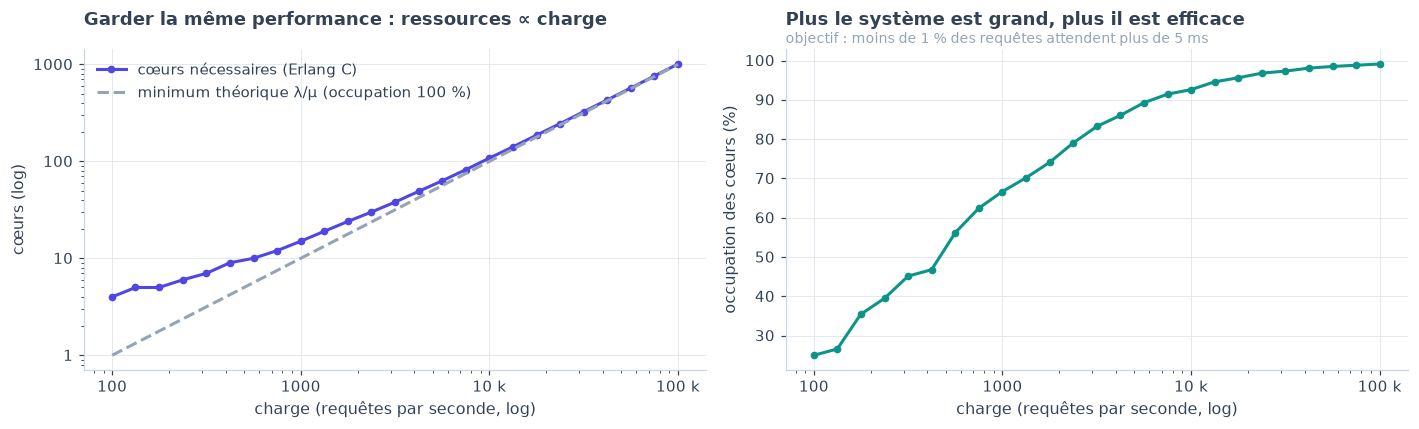

In [2]:
def coeurs_necessaires(lam, mu=100.0, t=0.005, cible=0.01):
    c = max(1, math.ceil(lam / mu))
    while rq.erlang_c(c, lam / mu) * math.exp(-(c * mu - lam) * t) >= cible:
        c += 1
    return c

charges = np.unique(np.logspace(2, 5, 25).astype(int))
cn = np.array([coeurs_necessaires(float(l)) for l in charges])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax.loglog(charges, cn, "o-", color=INDIGO, ms=4, label="cœurs nécessaires (Erlang C)")
ax.loglog(charges, charges / 100, "--", color=GRAY, label="minimum théorique λ/µ (occupation 100 %)")
rq.plain_log_axis(ax)
ax.set_xlabel("charge (requêtes par seconde, log)"); ax.set_ylabel("cœurs (log)")
ax.set_title("Garder la même performance : ressources ∝ charge")
ax.legend(loc="upper left")
ax2.semilogx(charges, charges / 100 / cn * 100, "o-", color=TEAL, ms=4)
rq.plain_log_axis(ax2, "x")
ax2.set_xlabel("charge (requêtes par seconde, log)"); ax2.set_ylabel("occupation des cœurs (%)")
ax2.set_title("Plus le système est grand, plus il est efficace")
subtitle(ax2, "objectif : moins de 1 % des requêtes attendent plus de 5 ms")
plt.tight_layout(); plt.show()

Les ressources nécessaires croissent presque **linéairement** avec la charge : doubler
les cœurs permet de servir deux fois plus de requêtes à performance égale, ce qu'on
appelle une **scalabilité linéaire**. Le graphique de droite montre même un net effet
d'échelle : pour le même objectif, un petit service doit rester occupé à 25 % à peine,
alors qu'un grand peut dépasser 95 %, car les fluctuations s'y compensent mieux (c'est
la mutualisation du cours 3). Dans la réalité, c'est plutôt
l'inverse qui guette : le coût croît souvent **plus vite** que la charge, parce que
traiter une requête devient plus cher quand il y a plus de données, ou parce que les
machines doivent se coordonner (section 3).

> **À retenir.** La scalabilité se discute pour une croissance donnée : à ressources
> fixes, comment la performance se dégrade ; à performance fixe, comment les ressources
> doivent croître. L'idéal est la scalabilité linéaire.

## 2. Monter en gamme ou multiplier les machines (section *Approaches for Coping with Load* et introduction de la partie II)

Trois architectures pour ajouter des ressources :

- **mémoire partagée** (shared-memory) : une machine plus puissante, plus de cœurs, de
  mémoire et de disques ; tous les fils d'exécution voient la même mémoire. C'est la
  **montée en gamme** (scaling up, scalabilité verticale) ;
- **disques partagés** (shared-disk) : plusieurs machines avec leurs propres processeurs
  et mémoire, mais un même ensemble de disques accessible par un réseau rapide (NAS, SAN) ;
  la contention et les verrous limitent son extensibilité ;
- **rien de partagé** (shared-nothing) : des nœuds indépendants, chacun avec ses
  processeurs, sa mémoire et ses disques, qui ne se coordonnent que par messages sur un
  réseau ordinaire. C'est la **multiplication des machines** (scaling out, scalabilité
  horizontale).

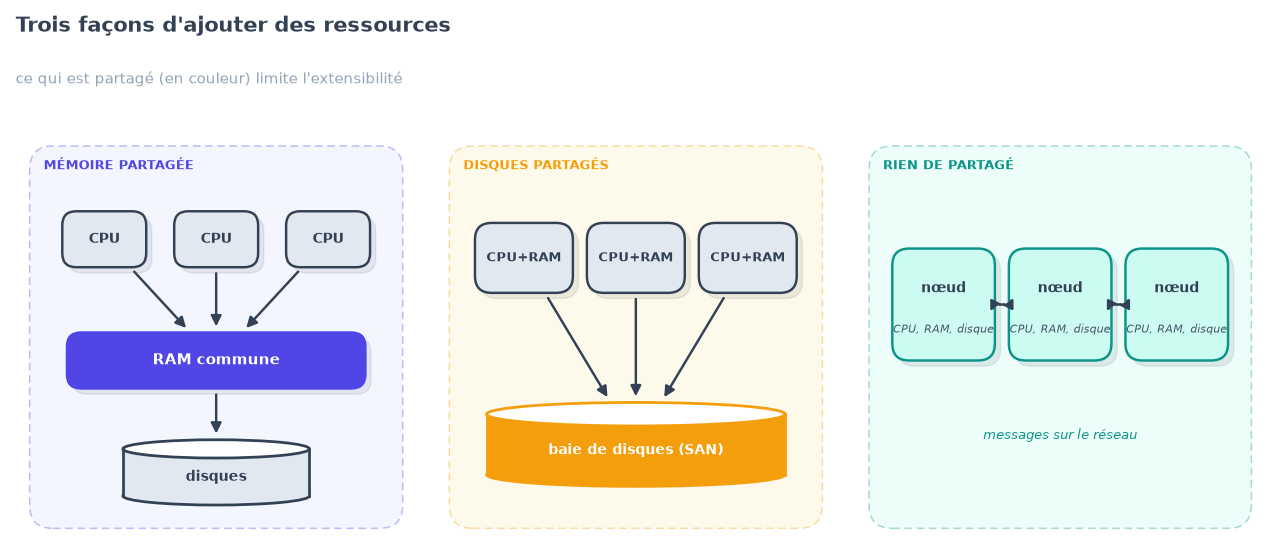

In [3]:
d = Diagram(13.5, 4.8, title="Trois façons d'ajouter des ressources",
            subtitle="ce qui est partagé (en couleur) limite l'extensibilité")
# mémoire partagée
d.group(0.2, 0.2, 4.2, 4.3, "mémoire partagée", color=INDIGO)
d.box("ram", 2.2, 2.0, "RAM commune", color=INDIGO, w=3.2, h=0.6, filled=True, fontsize=9.5)
for i, x in enumerate([1.0, 2.2, 3.4]):
    d.box(f"c{i}", x, 3.3, "CPU", color=SLATE, w=0.9, h=0.6, fontsize=9)
    d.arrow(f"c{i}", "ram")
d.box("disk0", 2.2, 0.8, "disques", color=SLATE, kind="db", w=2.0, h=0.7, fontsize=9)
d.arrow("ram", "disk0")
# disques partagés
d.group(4.7, 0.2, 8.7, 4.3, "disques partagés", color=AMBER)
d.box("san", 6.7, 1.1, "baie de disques (SAN)", color=AMBER, kind="db", w=3.2, h=0.9, filled=True, fontsize=9)
for i, x in enumerate([5.5, 6.7, 7.9]):
    d.box(f"n{i}", x, 3.1, "CPU+RAM", color=SLATE, w=1.05, h=0.75, fontsize=8.5)
    d.arrow(f"n{i}", "san")
# rien de partagé
d.group(9.2, 0.2, 13.3, 4.3, "rien de partagé", color=TEAL)
for i, x in enumerate([10.0, 11.25, 12.5]):
    d.box(f"s{i}", x, 2.6, "nœud", sub="CPU, RAM, disque", color=TEAL, w=1.1, h=1.2, fontsize=9)
d.arrow("s0", "s1", both=True, style="dashed")
d.arrow("s1", "s2", both=True, style="dashed")
d.note(11.25, 1.2, "messages sur le réseau", color=TEAL, fontsize=8.5)
d.show()

**Le problème de la montée en gamme est le coût.** Une machine deux fois plus puissante
coûte nettement plus du double, et ses goulets d'étranglement internes l'empêchent de
traiter deux fois plus de charge. Illustrons avec un **barème fictif** mais réaliste dans
sa forme : le prix horaire d'une machine croît comme $c^{1,3}$ en nombre de cœurs $c$, et
son débit suit une loi d'Amdahl (2 % du travail sérialisé par la contention interne).
Pour le rien-partagé, on aligne des machines de 16 cœurs, avec un petit surcoût de
coordination (le débit est divisé par $1 + 0{,}01\,(k-1)$ pour $k$ machines).

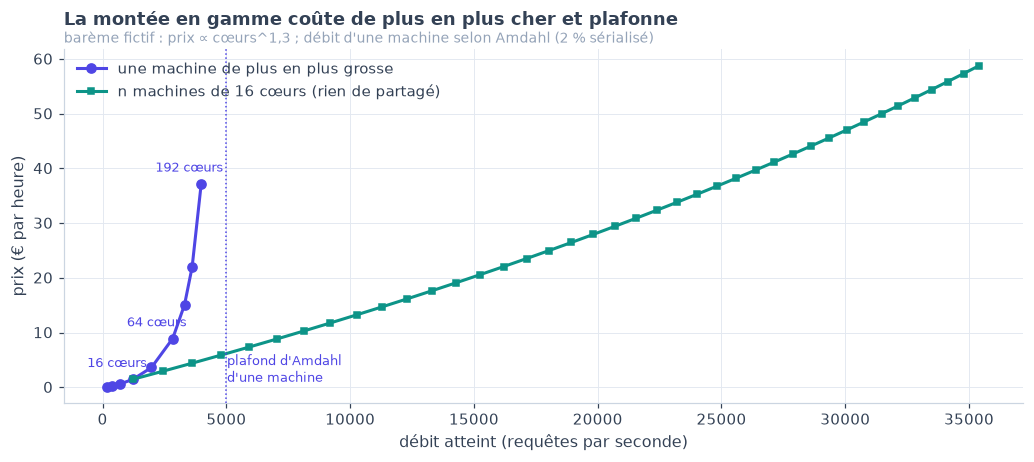

In [4]:
prix = lambda c: 0.04 * c ** 1.3                 # euros par heure, barème fictif
debit_machine = lambda c: 100 * rq.amdahl(c, 0.98)   # req/s, 100 req/s par cœur idéalement
cores_v = np.array([2, 4, 8, 16, 32, 64, 96, 128, 192])
v = pd.DataFrame({"cœurs": cores_v, "débit": debit_machine(cores_v), "prix": prix(cores_v)})
k = np.arange(1, 41)
h = pd.DataFrame({"machines": k, "débit": k * debit_machine(16) / (1 + 0.01 * (k - 1)), "prix": k * prix(16)})
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.plot(v["débit"], v["prix"], "o-", color=INDIGO, label="une machine de plus en plus grosse")
for _, r in v.iterrows():
    if r["cœurs"] in (16, 64, 192):
        ax.annotate(f"{r['cœurs']:.0f} cœurs", (r["débit"], r["prix"]), (-30, 8), textcoords="offset points",
                    fontsize=8.5, color=INDIGO)
ax.plot(h["débit"], h["prix"], "s-", color=TEAL, ms=3.5, label="n machines de 16 cœurs (rien de partagé)")
ax.axvline(debit_machine(10_000), color=INDIGO, ls=":", lw=1)
ax.text(debit_machine(10_000) * 1.01, 1, "plafond d'Amdahl\nd'une machine", color=INDIGO, fontsize=8.5)
ax.set_xlabel("débit atteint (requêtes par seconde)"); ax.set_ylabel("prix (€ par heure)")
ax.set_title("La montée en gamme coûte de plus en plus cher et plafonne")
subtitle(ax, "barème fictif : prix ∝ cœurs^1,3 ; débit d'une machine selon Amdahl (2 % sérialisé)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

La grosse machine est compétitive tant qu'elle reste moyenne ; au-delà, chaque requête
par seconde supplémentaire coûte de plus en plus cher, et un plafond infranchissable
apparaît (une machine ne dépassera jamais 50 fois le débit d'un cœur avec 2 % de travail
sérialisé). L'architecture sans partage peut, elle, croître presque linéairement, choisir
le matériel au meilleur rapport prix/performance, ajuster ses ressources à la hausse
comme à la baisse, et tolérer la perte d'un centre de données. Le prix à payer : il faut
découper explicitement les données (partitionnement, chapitre
6) et affronter toute la complexité des systèmes distribués (chapitre
8). En pratique, on combine souvent les deux : quelques machines
raisonnablement puissantes.

> **À retenir.** Monter en gamme (mémoire partagée) est simple mais coûte de plus en plus
> cher et plafonne ; les disques partagés butent sur la contention ; le rien-partagé
> passe à l'échelle presque linéairement, au prix du découpage des données et de la
> complexité des systèmes distribués.